In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print('Training images shape:', x_train.shape)
print('Training labels shape:', y_train.shape)
print('Test images shape:', x_test.shape)
print('Test labels shape:', y_test.shape)


Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)


In [5]:
print('Number of training samples:', len(x_train))
print('Number of test samples:', len(x_test))
print('Image dimensions:', x_train[0].shape)
print('Pixel data type:', x_train.dtype)
print('Minimum pixel value:', x_train.min())
print('Maximum pixel value:', x_train.max())
print('Unique target labels:', np.unique(y_train))

Number of training samples: 60000
Number of test samples: 10000
Image dimensions: (28, 28)
Pixel data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255
Unique target labels: [0 1 2 3 4 5 6 7 8 9]


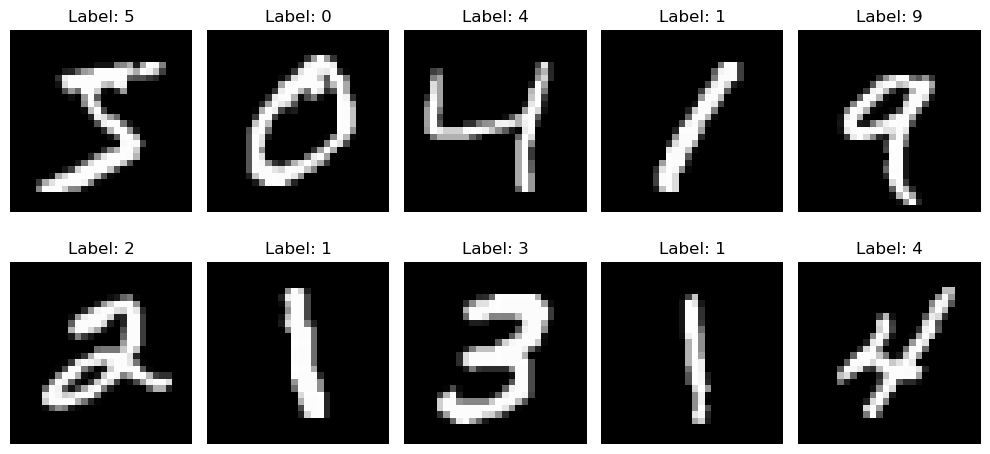

In [3]:
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'Label: {y_train[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure and characteristics of the MNIST handwritten digit dataset before applying machine learning models.

The analysis includes:
- Dataset dimensions
- Class distribution
- Missing values
- Duplicate images
- Pixel value distribution
- Visualization of representative images

In [4]:
print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test data shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)


### 4.1 Class Distribution

In [5]:
print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

Training class distribution:
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


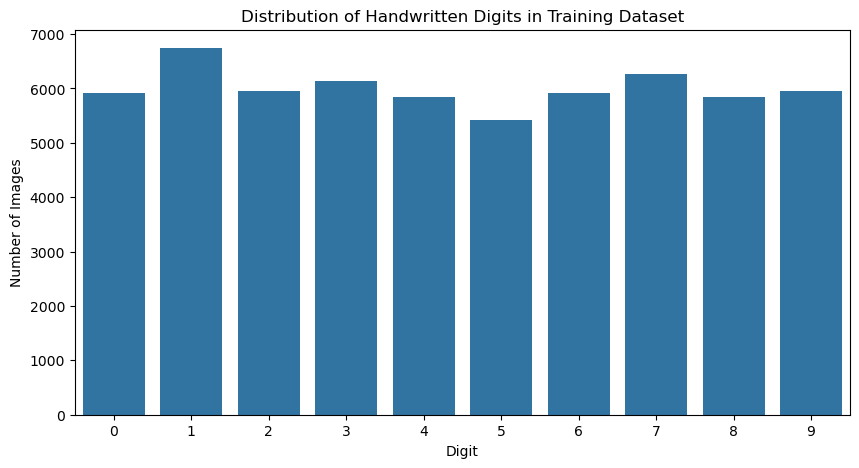

In [6]:
plt.figure(figsize=(10, 5))

sns.countplot(x=y_train)

plt.title("Distribution of Handwritten Digits in Training Dataset")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.show()

### 4.2 Missing Value Analysis

In [7]:
print("Missing values in training images:", np.isnan(x_train).sum())
print("Missing values in test images:", np.isnan(x_test).sum())

print("Missing values in training labels:", np.isnan(y_train).sum())
print("Missing values in test labels:", np.isnan(y_test).sum())

Missing values in training images: 0
Missing values in test images: 0
Missing values in training labels: 0
Missing values in test labels: 0


### 4.3 Duplicate Image Analysis

In [8]:
# Reshape each 28x28 image into a single row of 784 pixels
x_train_flat_temp = x_train.reshape(x_train.shape[0], -1)

# Count unique images
unique_images = np.unique(x_train_flat_temp, axis=0)

print("Total training images:", len(x_train_flat_temp))
print("Unique training images:", len(unique_images))
print("Duplicate training images:", 
      len(x_train_flat_temp) - len(unique_images))

Total training images: 60000
Unique training images: 60000
Duplicate training images: 0


### 4.4 Pixel Intensity Analysis

In [9]:
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Mean pixel value:", x_train.mean())
print("Standard deviation of pixel values:", x_train.std())

Minimum pixel value: 0
Maximum pixel value: 255
Mean pixel value: 33.318421449829934
Standard deviation of pixel values: 78.56748998339798


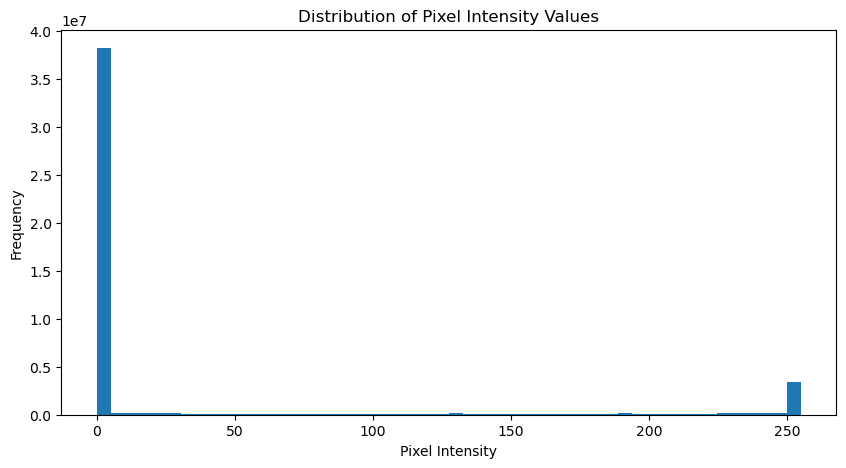

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(x_train.flatten(), bins=50)

plt.title("Distribution of Pixel Intensity Values")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

### 4.5 Visualization of Different Digit Classes

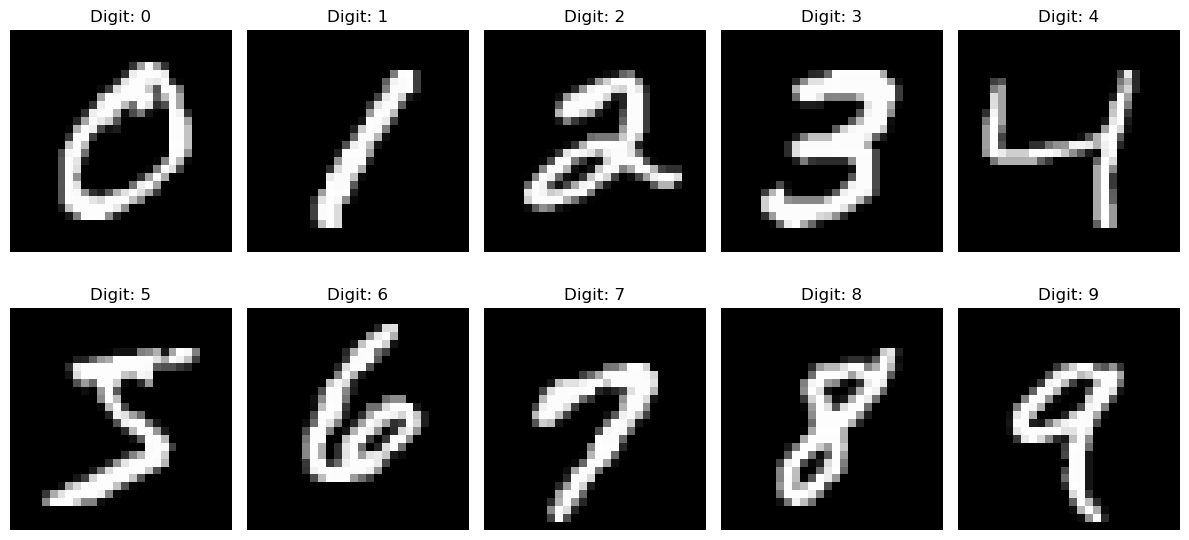

In [11]:
plt.figure(figsize=(12, 6))

for digit in range(10):
    index = np.where(y_train == digit)[0][0]
    
    plt.subplot(2, 5, digit + 1)
    plt.imshow(x_train[index], cmap='gray')
    plt.title(f"Digit: {digit}")
    plt.axis('off')

plt.tight_layout()
plt.show()


### EDA Findings

The MNIST dataset contains handwritten digit images belonging to 10 classes, ranging from 0 to 9.
The training dataset contains 60,000 images and the test dataset contains 10,000 images. Each image has dimensions of 28 × 28 pixels.
The target variable consists of 10 digit classes. The class distribution was analyzed to determine whether the dataset is balanced.
Missing-value analysis was performed on both images and target labels.
Duplicate image analysis was also performed to identify potential duplicate observations.
Pixel intensity values were analyzed to understand the grayscale distribution of the images. The pixel values range from 0 to 255.
Sample images from all ten digit classes were visualized to understand the variation in handwritten representations.

## 5. Data Preprocessing

The MNIST images are 28 × 28 grayscale images. Before applying machine learning algorithms, the images are converted into a suitable feature representation and pixel values are normalized.

The preprocessing steps are:

1. Flatten each 28 × 28 image into 784 features.
2. Normalize pixel values from the range 0–255 to 0–1.
3. Split the training data into training and validation sets.
4. Keep the test dataset separate for final model evaluation.

In [12]:
# Convert 28x28 images into 784-dimensional feature vectors

x_train_flat = x_train.reshape(x_train.shape[0], -1)
x_test_flat = x_test.reshape(x_test.shape[0], -1)

print("Original training shape:", x_train.shape)
print("Flattened training shape:", x_train_flat.shape)

print("Original test shape:", x_test.shape)
print("Flattened test shape:", x_test_flat.shape)

Original training shape: (60000, 28, 28)
Flattened training shape: (60000, 784)
Original test shape: (10000, 28, 28)
Flattened test shape: (10000, 784)


In [13]:
# Normalize pixel values from 0-255 to 0-1

x_train_scaled = x_train_flat.astype("float32") / 255.0
x_test_scaled = x_test_flat.astype("float32") / 255.0

print("Minimum scaled value:", x_train_scaled.min())
print("Maximum scaled value:", x_train_scaled.max())

Minimum scaled value: 0.0
Maximum scaled value: 1.0


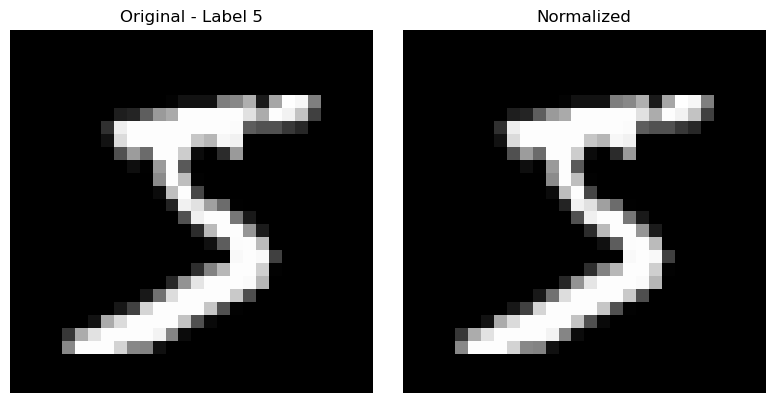

In [14]:
# Compare one image before and after preprocessing

sample_index = 0

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(x_train[sample_index], cmap="gray")
plt.title(f"Original - Label {y_train[sample_index]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(x_train_scaled[sample_index].reshape(28, 28), cmap="gray")
plt.title("Normalized")
plt.axis("off")
plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train_model, y_val = train_test_split(
    x_train_scaled,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Test data:", x_test_scaled.shape)

print("Training labels:", y_train_model.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

Training data: (54000, 784)
Validation data: (6000, 784)
Test data: (10000, 784)
Training labels: (54000,)
Validation labels: (6000,)
Test labels: (10000,)


In [16]:
print("Training class distribution:")
print(pd.Series(y_train_model).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

Training class distribution:
0    5331
1    6068
2    5362
3    5518
4    5258
5    4879
6    5326
7    5638
8    5266
9    5354
Name: count, dtype: int64

Validation class distribution:
0    592
1    674
2    596
3    613
4    584
5    542
6    592
7    627
8    585
9    595
Name: count, dtype: int64


### Preprocessing Findings

The original MNIST images have dimensions of 28 × 28 pixels. Each image was flattened into a 784-dimensional feature vector for use with traditional machine learning algorithms such as KNN and SVM.
Pixel values originally ranged from 0 to 255 and were normalized to a range of 0 to 1.
The original training dataset was divided into training and validation datasets using a 90:10 split. Stratified sampling was used to maintain the distribution of the ten digit classes.
The test dataset was kept separate and will only be used for final model evaluation.

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train_model, y_val = train_test_split(
    x_train_scaled,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Test data:", x_test_scaled.shape)

print("Training labels:", y_train_model.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

Training data: (54000, 784)
Validation data: (6000, 784)
Test data: (10000, 784)
Training labels: (54000,)
Validation labels: (6000,)
Test labels: (10000,)


In [18]:
print("Training class distribution:")
print(pd.Series(y_train_model).value_counts().sort_index())

print("\nValidation class distribution:")
print(pd.Series(y_val).value_counts().sort_index())

Training class distribution:
0    5331
1    6068
2    5362
3    5518
4    5258
5    4879
6    5326
7    5638
8    5266
9    5354
Name: count, dtype: int64

Validation class distribution:
0    592
1    674
2    596
3    613
4    584
5    542
6    592
7    627
8    585
9    595
Name: count, dtype: int64


## 6. K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a supervised classification algorithm that classifies a new observation based on the classes of its nearest neighboring observations.

For the MNIST dataset, the distance between handwritten digit images is calculated using their 784-dimensional feature representations.

The value of K determines the number of neighboring samples considered for classification.

In [19]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time

In [20]:
knn_model = KNeighborsClassifier(
    n_neighbors=3,
    n_jobs=-1
)

start_time = time.time()

knn_model.fit(X_train, y_train_model)

knn_training_time = time.time() - start_time

print("KNN training completed.")
print("Training time:", round(knn_training_time, 2), "seconds")

KNN training completed.
Training time: 0.31 seconds


In [21]:
start_time = time.time()

y_pred_knn = knn_model.predict(X_val)

knn_prediction_time = time.time() - start_time

print("Prediction completed.")
print("Prediction time:", round(knn_prediction_time, 2), "seconds")

Prediction completed.
Prediction time: 32.51 seconds


In [22]:
knn_accuracy = accuracy_score(y_val, y_pred_knn)

print("KNN Validation Accuracy:", round(knn_accuracy, 4))
print("KNN Validation Accuracy:", round(knn_accuracy * 100, 2), "%")

KNN Validation Accuracy: 0.9713
KNN Validation Accuracy: 97.13 %


In [23]:
print("KNN Classification Report:\n")

print(
    classification_report(
        y_val,
        y_pred_knn,
        digits=4
    )
)

KNN Classification Report:

              precision    recall  f1-score   support

           0     0.9752    0.9966    0.9858       592
           1     0.9451    0.9955    0.9697       674
           2     0.9747    0.9681    0.9714       596
           3     0.9706    0.9690    0.9698       613
           4     0.9759    0.9709    0.9734       584
           5     0.9794    0.9649    0.9721       542
           6     0.9864    0.9814    0.9839       592
           7     0.9730    0.9761    0.9745       627
           8     0.9854    0.9248    0.9541       585
           9     0.9549    0.9613    0.9581       595

    accuracy                         0.9713      6000
   macro avg     0.9721    0.9709    0.9713      6000
weighted avg     0.9716    0.9713    0.9713      6000



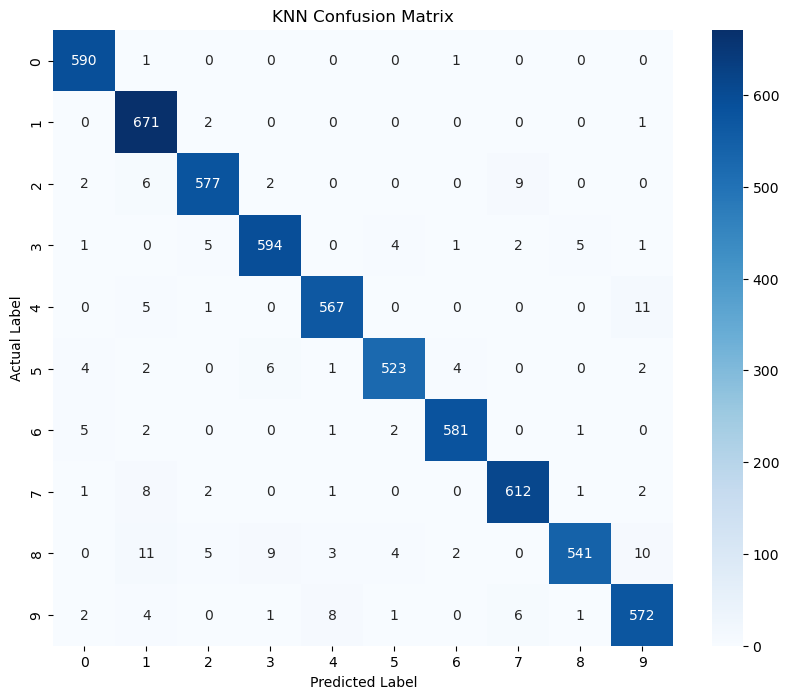

In [24]:
cm_knn = confusion_matrix(y_val, y_pred_knn)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [25]:
model_results = []

model_results.append({
    "Model": "KNN",
    "Accuracy": knn_accuracy,
    "Training Time (sec)": knn_training_time,
    "Prediction Time (sec)": knn_prediction_time
})

pd.DataFrame(model_results)

,Model,Accuracy,Training Time (sec),Prediction Time (sec)
0,KNN,0.971333,0.313379,32.510299


### KNN Model Findings

The K-Nearest Neighbors classifier was trained using the preprocessed MNIST training dataset.
The model was evaluated on the validation dataset using accuracy, precision, recall, F1-score, and a confusion matrix.
The confusion matrix provides a class-wise view of the predictions and helps identify which handwritten digits are more frequently confused with each other.
The KNN results will be compared with other classification models later in the project to determine the most suitable model for production.

### KNN Hyperparameter Experiment

The number of neighbors (K) can affect the performance of the KNN classifier. Different values of K are tested to determine whether model performance can be improved.

In [27]:
knn_comparison = []

for k in [3, 5, 7]:
    print(f"Training KNN with K={k}...")
    
    start_time = time.time()
    
    model = KNeighborsClassifier(
        n_neighbors=k,
        n_jobs=-1
    )
    
    model.fit(X_train, y_train_model)
    
    training_time = time.time() - start_time
    
    start_time = time.time()
    
    predictions = model.predict(X_val)
    
    prediction_time = time.time() - start_time
    
    accuracy = accuracy_score(y_val, predictions)
    
    knn_comparison.append({
        "K": k,
        "Accuracy": accuracy,
        "Training Time (sec)": training_time,
        "Prediction Time (sec)": prediction_time
    })

knn_comparison_df = pd.DataFrame(knn_comparison)

knn_comparison_df

Training KNN with K=3...
Training KNN with K=5...
Training KNN with K=7...


,K,Accuracy,Training Time (sec),Prediction Time (sec)
0,3,0.971333,0.069915,26.514306
1,5,0.968333,0.163940,28.268708
2,7,0.966167,0.160191,28.522547


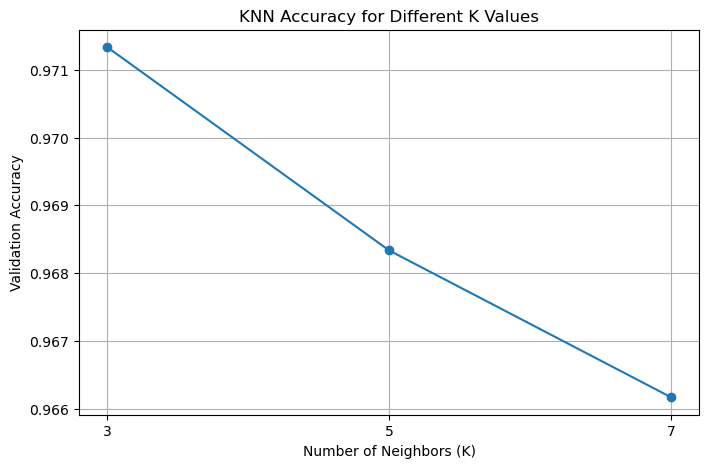

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    knn_comparison_df["K"],
    knn_comparison_df["Accuracy"],
    marker="o"
)

plt.title("KNN Accuracy for Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Validation Accuracy")
plt.xticks([3, 5, 7])
plt.grid(True)

plt.show()

### KNN Hyperparameter Findings

Three K values (3, 5, and 7) were evaluated using the validation dataset.

The K=3 configuration achieved the highest validation accuracy of approximately 97.13%. Increasing the number of neighbors to 5 and 7 resulted in lower validation accuracy.

Therefore, K=3 was selected as the preferred KNN configuration among the tested values.

In [29]:
best_knn_model = KNeighborsClassifier(
    n_neighbors=3,
    n_jobs=-1
)

best_knn_model.fit(X_train, y_train_model)

print("Final KNN model selected with K=3.")

Final KNN model selected with K=3.


## 7. Support Vector Machine (SVM)

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification.

SVM attempts to find a decision boundary that separates different classes while maximizing the margin between classes.

For this project, SVM will be evaluated as an alternative to KNN for handwritten digit classification.

The SVM model will be evaluated using validation accuracy, precision, recall, F1-score, training time, prediction time, and a confusion matrix.

In [30]:
from sklearn.svm import LinearSVC

In [31]:
svm_model = LinearSVC(
    C=1.0,
    max_iter=5000,
    random_state=42
)

start_time = time.time()

svm_model.fit(X_train, y_train_model)

svm_training_time = time.time() - start_time

print("SVM training completed.")
print("Training time:", round(svm_training_time, 2), "seconds")

SVM training completed.
Training time: 267.94 seconds


In [32]:
start_time = time.time()

y_pred_svm = svm_model.predict(X_val)

svm_prediction_time = time.time() - start_time

print("Prediction completed.")
print("Prediction time:", round(svm_prediction_time, 2), "seconds")

Prediction completed.
Prediction time: 0.15 seconds


In [33]:
svm_accuracy = accuracy_score(y_val, y_pred_svm)

print("SVM Validation Accuracy:", round(svm_accuracy, 4))
print("SVM Validation Accuracy:", round(svm_accuracy * 100, 2), "%")

SVM Validation Accuracy: 0.9152
SVM Validation Accuracy: 91.52 %


In [34]:
print("SVM Classification Report:\n")

print(
    classification_report(
        y_val,
        y_pred_svm,
        digits=4
    )
)

SVM Classification Report:

              precision    recall  f1-score   support

           0     0.9400    0.9797    0.9595       592
           1     0.9495    0.9763    0.9627       674
           2     0.9135    0.8859    0.8995       596
           3     0.8849    0.8907    0.8878       613
           4     0.9225    0.9178    0.9202       584
           5     0.8966    0.8801    0.8883       542
           6     0.9392    0.9392    0.9392       592
           7     0.9321    0.9203    0.9262       627
           8     0.8887    0.8598    0.8740       585
           9     0.8760    0.8908    0.8833       595

    accuracy                         0.9152      6000
   macro avg     0.9143    0.9141    0.9141      6000
weighted avg     0.9149    0.9152    0.9149      6000



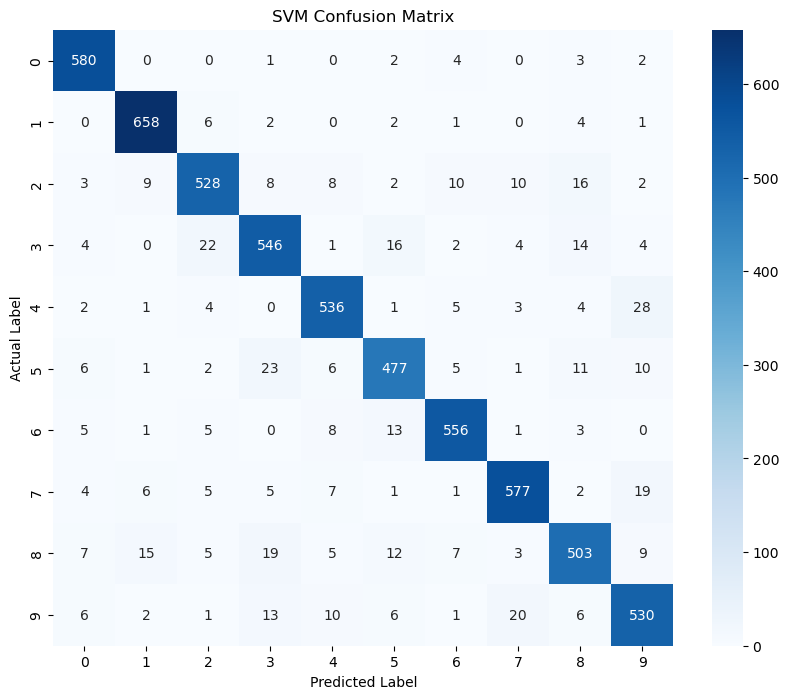

In [35]:
cm_svm = confusion_matrix(y_val, y_pred_svm)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [36]:
model_results.append({
    "Model": "Linear SVM",
    "Accuracy": svm_accuracy,
    "Training Time (sec)": svm_training_time,
    "Prediction Time (sec)": svm_prediction_time
})

model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,Accuracy,Training Time (sec),Prediction Time (sec)
0,KNN,0.971333,0.313379,32.510299
1,Linear SVM,0.915167,267.944000,0.145974


### SVM Model Findings

The Linear Support Vector Machine classifier was trained using the preprocessed MNIST dataset.

The model was evaluated using validation accuracy, precision, recall, F1-score, and a confusion matrix.

The SVM training and prediction times were also recorded to compare computational performance against the KNN classifier.

The validation performance of SVM will be compared with KNN and the neural network model in the final model comparison stage.

### SVM Hyperparameter Experiment

The regularization parameter C controls the trade-off between achieving a wider decision margin and correctly classifying the training observations.

A second Linear SVM experiment is performed with C=10 to determine whether increasing the regularization parameter improves validation performance.

In [37]:
svm_c10 = LinearSVC(
    C=10.0,
    max_iter=5000,
    random_state=42
)

start_time = time.time()

svm_c10.fit(X_train, y_train_model)

svm_c10_training_time = time.time() - start_time

start_time = time.time()

y_pred_svm_c10 = svm_c10.predict(X_val)

svm_c10_prediction_time = time.time() - start_time

svm_c10_accuracy = accuracy_score(y_val, y_pred_svm_c10)

print("SVM C=10 Accuracy:", round(svm_c10_accuracy * 100, 2), "%")
print("Training time:", round(svm_c10_training_time, 2), "seconds")
print("Prediction time:", round(svm_c10_prediction_time, 2), "seconds")

SVM C=10 Accuracy: 91.25 %
Training time: 528.67 seconds
Prediction time: 0.05 seconds


In [38]:
model_results.append({
    "Model": "Linear SVM (C=10)",
    "Accuracy": svm_c10_accuracy,
    "Training Time (sec)": svm_c10_training_time,
    "Prediction Time (sec)": svm_c10_prediction_time
})

pd.DataFrame(model_results)

,Model,Accuracy,Training Time (sec),Prediction Time (sec)
0,KNN,0.971333,0.313379,32.510299
1,Linear SVM,0.915167,267.944000,0.145974
2,Linear SVM (C=10),0.912500,528.669023,0.051739


### SVM Hyperparameter Findings

Two Linear SVM configurations were evaluated using C=1 and C=10.

The Linear SVM with C=1 achieved a validation accuracy of 91.52%, while increasing C to 10 resulted in a slightly lower accuracy of 91.25%.

The C=10 configuration also required substantially more training time (approximately 528.67 seconds compared with 267.94 seconds for C=1).

Therefore, C=1 is preferred over C=10 among the tested Linear SVM configurations because it provides better validation accuracy with lower training time.

## 8. Neural Network

A neural network is used to learn patterns from the 784 pixel features of the handwritten digit images.

The network contains:
- 784 input features representing the flattened 28 × 28 image
- Two hidden layers for learning nonlinear patterns
- 10 output neurons representing digits 0–9

The model will be evaluated using validation accuracy, precision, recall, F1-score, confusion matrix, and training/prediction time.

In [39]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

In [40]:
nn_model = Sequential([
    Input(shape=(784,)),
    
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    
    Dense(10, activation="softmax")
])

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
nn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [42]:
start_time = time.time()

history = nn_model.fit(
    X_train,
    y_train_model,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

nn_training_time = time.time() - start_time

print("Neural Network training completed.")
print("Training time:", round(nn_training_time, 2), "seconds")

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9015 - loss: 0.3505 - val_accuracy: 0.9465 - val_loss: 0.1883
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9566 - loss: 0.1452 - val_accuracy: 0.9640 - val_loss: 0.1411
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9700 - loss: 0.1015 - val_accuracy: 0.9688 - val_loss: 0.1102
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9772 - loss: 0.0756 - val_accuracy: 0.9692 - val_loss: 0.1047
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9820 - loss: 0.0594 - val_accuracy: 0.9717 - val_loss: 0.0966
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9857 - loss: 0.0477 - val_accuracy: 0.9717 - val_loss: 0.1004
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9877 - loss: 0.0397 - val_accuracy: 0.9720 - val_loss: 0.1036
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9899 - loss: 0.0327 - val_accuracy: 0.

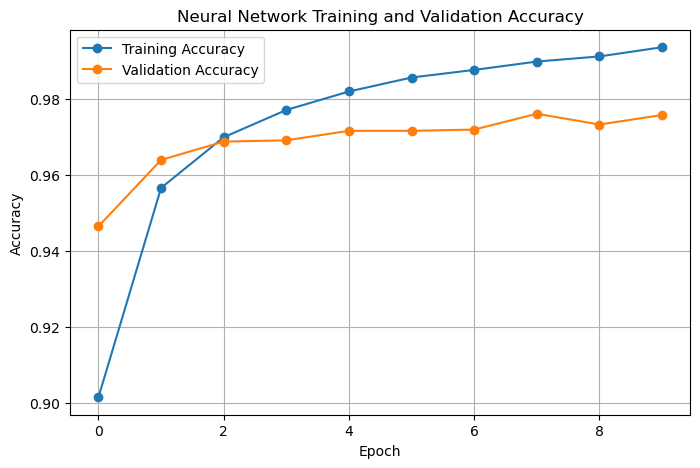

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Neural Network Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()

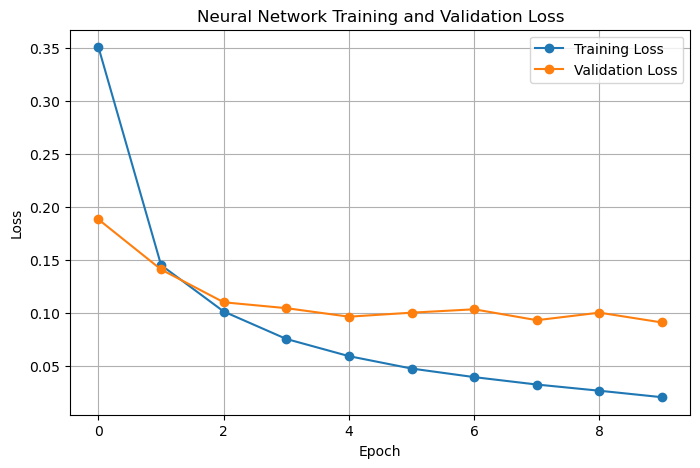

In [44]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [45]:
start_time = time.time()

nn_pred_prob = nn_model.predict(X_val, verbose=0)

nn_prediction_time = time.time() - start_time

y_pred_nn = np.argmax(nn_pred_prob, axis=1)

print("Prediction completed.")
print("Prediction time:", round(nn_prediction_time, 2), "seconds")

Prediction completed.
Prediction time: 1.1 seconds


In [46]:
nn_accuracy = accuracy_score(y_val, y_pred_nn)

print(
    "Neural Network Validation Accuracy:",
    round(nn_accuracy * 100, 2),
    "%"
)

Neural Network Validation Accuracy: 97.58 %


In [47]:
print("Neural Network Classification Report:\n")

print(
    classification_report(
        y_val,
        y_pred_nn,
        digits=4
    )
)

Neural Network Classification Report:

              precision    recall  f1-score   support

           0     0.9750    0.9899    0.9824       592
           1     0.9838    0.9896    0.9867       674
           2     0.9763    0.9664    0.9713       596
           3     0.9949    0.9527    0.9733       613
           4     0.9747    0.9897    0.9822       584
           5     0.9673    0.9815    0.9744       542
           6     0.9880    0.9764    0.9822       592
           7     0.9700    0.9793    0.9746       627
           8     0.9516    0.9744    0.9628       585
           9     0.9760    0.9580    0.9669       595

    accuracy                         0.9758      6000
   macro avg     0.9758    0.9758    0.9757      6000
weighted avg     0.9760    0.9758    0.9758      6000



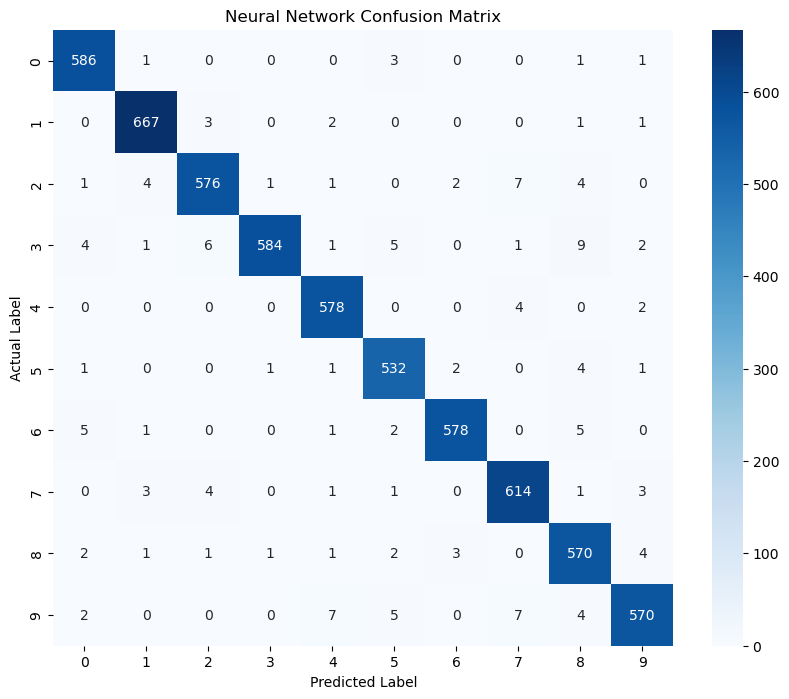

In [48]:
cm_nn = confusion_matrix(y_val, y_pred_nn)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_nn,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Neural Network Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [49]:
model_results.append({
    "Model": "Neural Network",
    "Accuracy": nn_accuracy,
    "Training Time (sec)": nn_training_time,
    "Prediction Time (sec)": nn_prediction_time
})

model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,Accuracy,Training Time (sec),Prediction Time (sec)
0,KNN,0.971333,0.313379,32.510299
1,Linear SVM,0.915167,267.944000,0.145974
2,Linear SVM (C=10),0.912500,528.669023,0.051739
3,Neural Network,0.975833,45.810667,1.101324


## 9. Model Comparison

The performance of the evaluated models is compared using validation accuracy, training time, and prediction time.

The comparison helps identify the model that provides the best balance between classification performance and computational efficiency.

In [50]:
model_results_df = pd.DataFrame(model_results)

model_results_df

,Model,Accuracy,Training Time (sec),Prediction Time (sec)
0,KNN,0.971333,0.313379,32.510299
1,Linear SVM,0.915167,267.944000,0.145974
2,Linear SVM (C=10),0.912500,528.669023,0.051739
3,Neural Network,0.975833,45.810667,1.101324


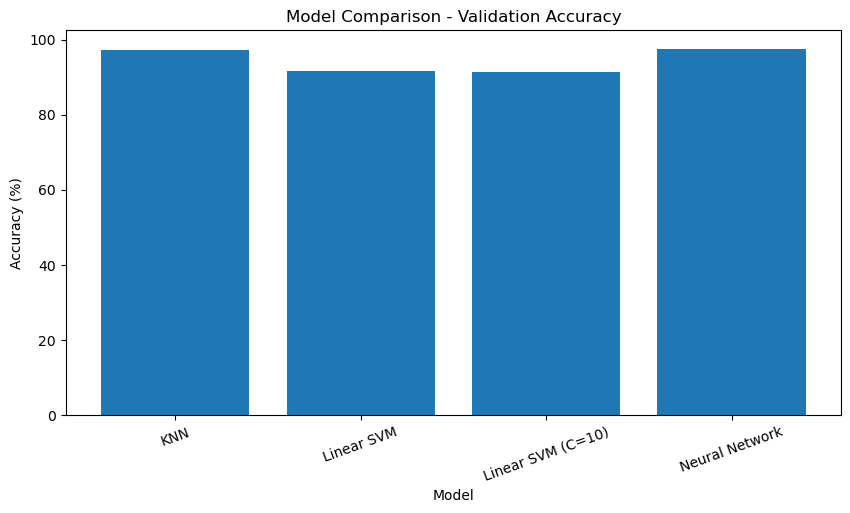

In [51]:
plt.figure(figsize=(10, 5))

plt.bar(
    model_results_df["Model"],
    model_results_df["Accuracy"] * 100
)

plt.title("Model Comparison - Validation Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20)

plt.show()

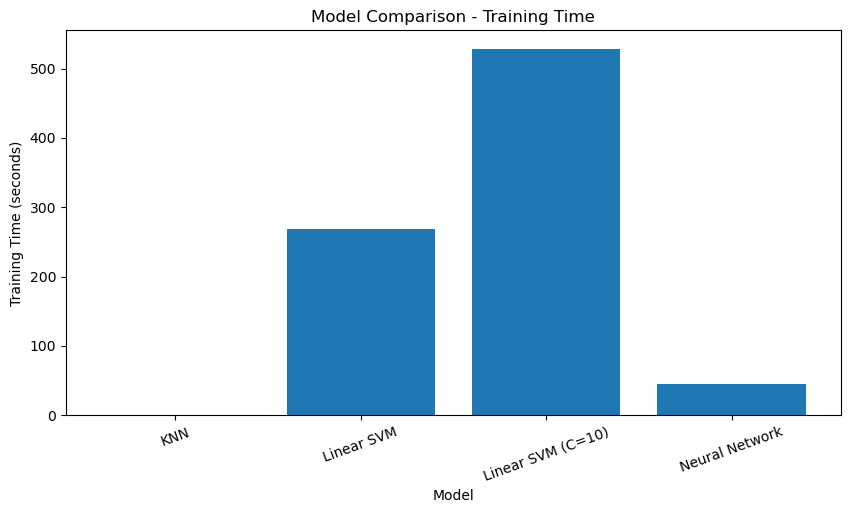

In [52]:
plt.figure(figsize=(10, 5))

plt.bar(
    model_results_df["Model"],
    model_results_df["Training Time (sec)"]
)

plt.title("Model Comparison - Training Time")
plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=20)

plt.show()

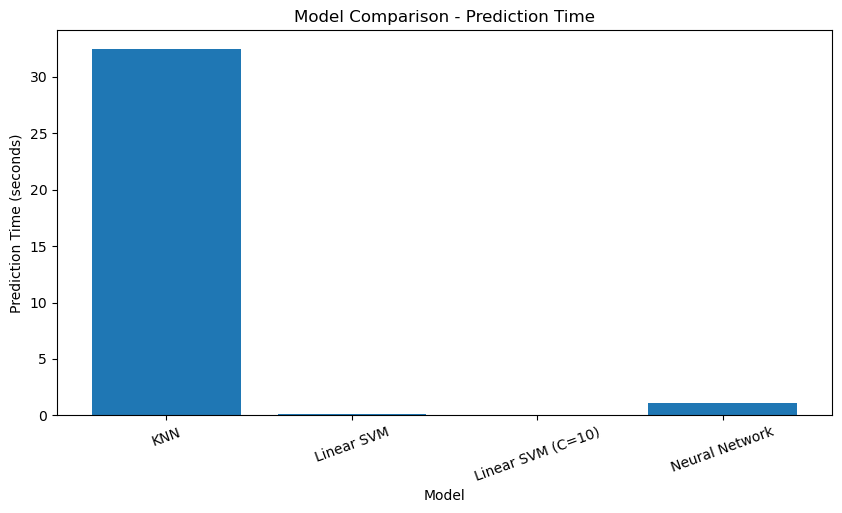

In [53]:
plt.figure(figsize=(10, 5))

plt.bar(
    model_results_df["Model"],
    model_results_df["Prediction Time (sec)"]
)

plt.title("Model Comparison - Prediction Time")
plt.xlabel("Model")
plt.ylabel("Prediction Time (seconds)")
plt.xticks(rotation=20)

plt.show()

## 9. Final Model Evaluation

The Neural Network achieved the highest validation accuracy among the evaluated models. Therefore, it is selected for final evaluation using the unseen MNIST test dataset.

The final evaluation includes accuracy, precision, recall, F1-score, and a confusion matrix.

In [54]:
start_time = time.time()

nn_test_prob = nn_model.predict(x_test_scaled, verbose=0)

nn_test_prediction_time = time.time() - start_time

y_pred_test = np.argmax(nn_test_prob, axis=1)

print("Test prediction completed.")
print("Prediction time:", round(nn_test_prediction_time, 2), "seconds")

Test prediction completed.
Prediction time: 1.71 seconds


In [55]:
nn_test_accuracy = accuracy_score(y_test, y_pred_test)

print(
    "Neural Network Test Accuracy:",
    round(nn_test_accuracy * 100, 2),
    "%"
)

Neural Network Test Accuracy: 97.51 %


In [56]:
print("Neural Network Test Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_test,
        digits=4
    )
)

Neural Network Test Classification Report:

              precision    recall  f1-score   support

           0     0.9818    0.9898    0.9858       980
           1     0.9885    0.9868    0.9877      1135
           2     0.9841    0.9612    0.9725      1032
           3     0.9800    0.9693    0.9746      1010
           4     0.9695    0.9695    0.9695       982
           5     0.9701    0.9809    0.9755       892
           6     0.9800    0.9718    0.9759       958
           7     0.9636    0.9786    0.9710      1028
           8     0.9644    0.9743    0.9694       974
           9     0.9673    0.9683    0.9678      1009

    accuracy                         0.9751     10000
   macro avg     0.9749    0.9751    0.9750     10000
weighted avg     0.9752    0.9751    0.9751     10000



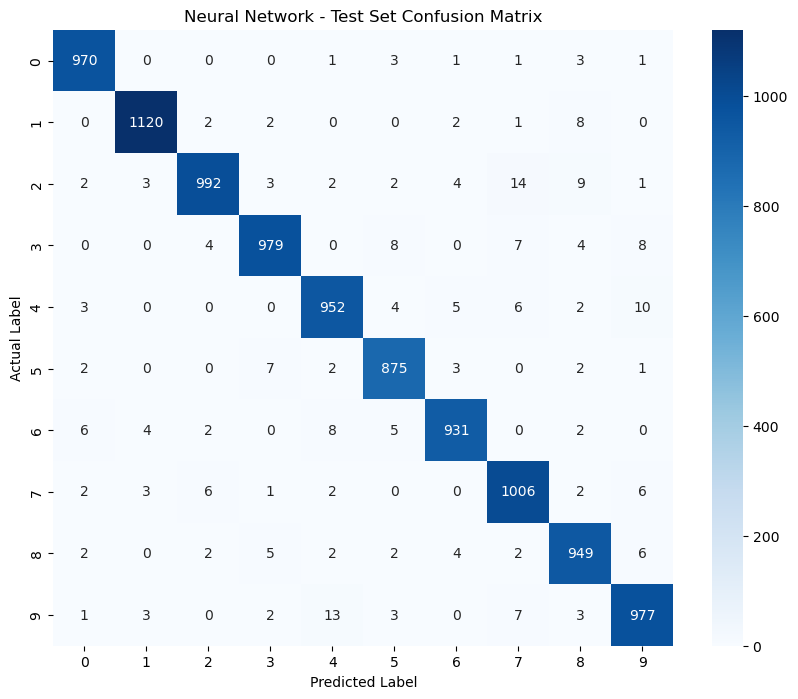

In [57]:
cm_test = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Neural Network - Test Set Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

### Final Model Evaluation Findings

The Neural Network was evaluated using the unseen MNIST test dataset.

The final test accuracy, precision, recall, F1-score, and confusion matrix were analyzed to determine the performance of the selected classifier on unseen handwritten digit images.

## 10. Model Comparison and Best Model

The evaluated models are compared based on their classification performance and computational performance.

The models evaluated are:
- K-Nearest Neighbors (KNN)
- Linear Support Vector Machine (SVM)
- Neural Network

Based on the validation results, the model with the best classification performance is selected as the recommended classifier.

In [58]:
model_results_df

,Model,Accuracy,Training Time (sec),Prediction Time (sec)
0,KNN,0.971333,0.313379,32.510299
1,Linear SVM,0.915167,267.944000,0.145974
2,Linear SVM (C=10),0.912500,528.669023,0.051739
3,Neural Network,0.975833,45.810667,1.101324


### Model Comparison Findings

Among the evaluated models, the Neural Network achieved the highest validation accuracy of 97.58%, followed by KNN with 97.13%. Linear SVM with C=1 achieved 91.52%, while Linear SVM with C=10 achieved 91.25%.

Based on validation accuracy, the Neural Network is selected as the best-performing classifier among the evaluated models.

## 11. Handwritten Digit Classification

The selected Neural Network classifier is used to classify an unseen handwritten digit image.

In [59]:
sample_index = 0

sample_image = x_test[sample_index]
actual_digit = y_test[sample_index]

sample_image_scaled = sample_image.reshape(1, 784).astype("float32") / 255.0

prediction_probability = nn_model.predict(
    sample_image_scaled,
    verbose=0
)

predicted_digit = np.argmax(prediction_probability)

print("Actual Digit:", actual_digit)
print("Predicted Digit:", predicted_digit)

Actual Digit: 7
Predicted Digit: 7


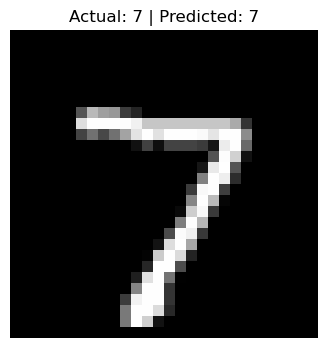

In [60]:
plt.figure(figsize=(4, 4))

plt.imshow(sample_image, cmap="gray")

plt.title(
    f"Actual: {actual_digit} | Predicted: {predicted_digit}"
)

plt.axis("off")
plt.show()

## 12. Challenges Faced and Techniques Used

| Challenge | Technique Used | Reason |
|---|---|---|
| Image data was provided in 28 × 28 pixel format | Image flattening into 784 features | Required for traditional machine learning models such as KNN and SVM |
| Pixel values ranged from 0 to 255 | Pixel normalization to 0–1 | Provides a standardized feature range |
| Training and validation data needed to maintain class proportions | Stratified train-validation split | Maintains representation of all ten digit classes |
| Different models produced different levels of performance | Model comparison using validation results | Used to identify the better-performing classifier |
| KNN prediction required more time than the other evaluated models | Prediction time was measured during model comparison | Helps compare computational performance |
| SVM performance was lower than the other evaluated models | Tested different C values | Used to determine whether changing the regularization parameter improved performance |

## 13. Final Model Recommendation

The models were compared based on their validation accuracy, training time, and prediction time.

The Neural Network achieved the highest validation accuracy of 97.58% and a final test accuracy of 97.51%.

Therefore, the Neural Network is selected as the best-performing classifier for the handwritten digit recognition problem among the evaluated models.

## 14. Final Model Comparison

| Model | Validation Accuracy | Training Time (sec) | Prediction Time (sec) |
|---|---:|---:|---:|
| KNN (K=3) | 97.13% | 0.31 | 32.51 |
| Linear SVM (C=1) | 91.52% | 267.94 | 0.15 |
| Linear SVM (C=10) | 91.25% | 528.67 | 0.05 |
| Neural Network | 97.58% | 45.81 | 1.10 |

The Neural Network achieved the highest validation accuracy of 97.58%. The final test accuracy of the Neural Network was 97.51%.

Based on the observed classification performance, the Neural Network is selected as the best classifier for this project.

## 16. Conclusion

The MNIST handwritten digit dataset was analyzed and preprocessed successfully. The 28 × 28 pixel images were converted into 784-dimensional feature vectors and pixel values were normalized from 0–255 to 0–1.

Three classification approaches were evaluated: K-Nearest Neighbors, Linear Support Vector Machine, and Neural Network.

Among the evaluated models, the Neural Network achieved the highest validation accuracy of 97.58%. When evaluated on the unseen test dataset, the Neural Network achieved an accuracy of 97.51%.

Therefore, the Neural Network was selected as the best-performing classifier for the handwritten digit recognition problem.